In [57]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI

In [58]:
load_dotenv()

True

In [59]:
chat_model = ChatGoogleGenerativeAI(
    model="gemini-2.5-flash"
)

In [60]:
class SubState(TypedDict) :
    input_txt : str
    translated_text : str

In [61]:
def translate_text(state : SubState) :
    prompt = f"""
Translate the following text to Hindi.
Keep it natural and clear. Do not add extra content.

Text:
{state['input_txt']}
""".strip()

    translated_text = chat_model.invoke(prompt).content
    return {"translated_text" : translated_text}

In [62]:
subgraph_builder = StateGraph(SubState)

subgraph_builder.add_node('translate_text', translate_text)

subgraph_builder.add_edge(START, 'translate_text')
subgraph_builder.add_edge('translate_text', END)

subgraph = subgraph_builder.compile()

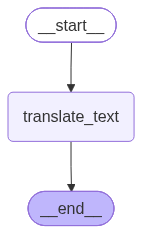

In [18]:
subgraph

In [63]:
class ParentState(TypedDict) :
    question : str
    answer_eng : str
    answer_hin : str

In [64]:
def generate_ans(state : ParentState) :
    answer = chat_model.invoke(f"You are a helpful assistant. Answer clearly.\n\nQuestion: {state['question']}").content
    return {'answer_eng' : answer}

In [65]:
def translate_ans(state : ParentState) :
    result = subgraph.invoke({'input_txt': state['answer_eng']})
    return {'answer_hin' : result['translated_text']}

In [66]:
parent_builder = StateGraph(ParentState)

parent_builder.add_node('answer', generate_ans)
parent_builder.add_node('translate', translate_ans)

parent_builder.add_edge(START, 'answer')
parent_builder.add_edge('answer', 'translate')
parent_builder.add_edge('translate', END)

In [67]:
graph = parent_builder.compile()

In [68]:
graph.invoke({'question': 'What is the capital of Australia'})

{'question': 'What is the capital of Australia',
 'answer_eng': 'The capital of Australia is **Canberra**.',
 'answer_hin': 'ऑस्ट्रेलिया की राजधानी **कैनबरा** है।'}